In [5]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
from NSC import NSC, Diffusor

In [529]:
'''web = [NSC(22.0, 328.0),
       NSC(200, 2500),
       NSC(37.0, 11.0)]
web[0].link(web[1], 0.5)
web[1].link(web[2], 2)
web[2].link(web[0], 1)'''

def plNSC(): return NSC(3*1.5, 10, tag='pl')  #plants shake in 3 dimensions
def wdNSC(): return NSC(2*1.5, 10, tag='wd') #vertical wind is ignored near surface

wcol = [NSC(2*1.5, 100, True), wdNSC(),wdNSC(),wdNSC(),wdNSC()]
pcol = [plNSC(), plNSC(), plNSC(), plNSC(), NSC(4*1.5, 10, True)]

for i in range(len(wcol)-1):
    wcol[i].link(wcol[i+1], 0.1)
    pcol[i].link(pcol[i+1], 1)
    wcol[i+1].link(pcol[i], 0.1)
wcol[-1].link(pcol[-1], 2)
web = wcol + pcol

In [530]:
#worker = Diffusor(web)
#worker.delta(worker.c, worker.t, worker.s, worker.q, worker.dist, worker.mask)

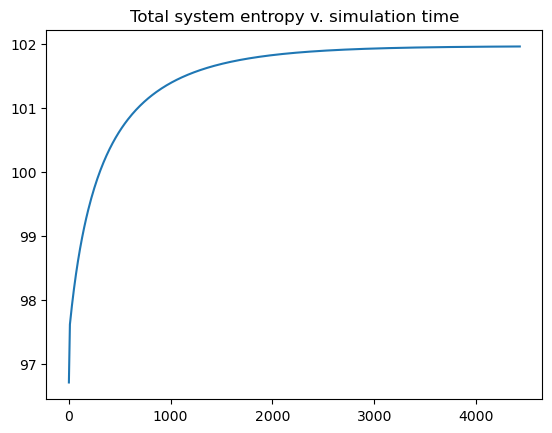

In [574]:
worker = Diffusor(web)

steps = 1000
cutflags = 0
cutthresh = 1e-3
brind = 0

history = np.zeros((steps, len(web)))
time = np.zeros(steps)
for i in range(steps):
    history[i] = worker.s
    time[i] = worker.time
    brind = i
    worker.update(default_step = 10)
    if (i > 10 and (np.sum(worker.s) - np.sum(history[i-10]))/(worker.time/time[i-10]) < cutthresh):
        if (cutflags > 10): break
        cutflags += 1
plt.title('Total system entropy v. simulation time')
plt.plot(time[:brind], np.nansum(history[:brind],axis=1))
#plt.plot(time)

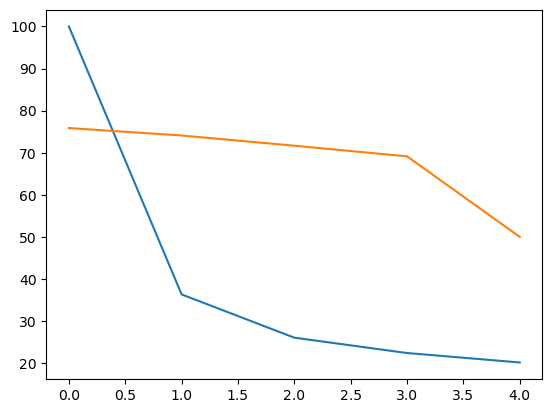

In [538]:
#plt.plot(np.log1p(worker.s))
plt.plot(worker.t[:5])   #wind component temperature
plt.plot(worker.t[5:]*5) #plant component temperature, scaled for visibility

Text(0.5, 0, 'steps')

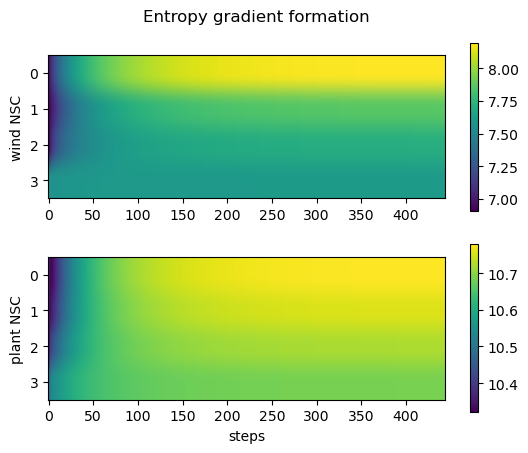

In [585]:
f, axarr = plt.subplots(2)
f.suptitle('Entropy gradient formation', x=0.45, y=0.95)
#f.tight_layout()f.
#plt.ylabel('iterations'); plt.xlabel('wind components');
a = axarr[0].imshow(history[:brind, 1:5].T, aspect=40); plt.colorbar(a, ax=axarr[0])
a = axarr[1].imshow(history[:brind, 5:-1].T, aspect=40); plt.colorbar(a, ax=axarr[1])
axarr[0].set_ylabel('wind NSC');# axarr[0].set_ylabel('step')
axarr[1].set_ylabel('plant NSC'); axarr[1].set_xlabel('steps')

In [452]:
print(worker.s)
print(worker.t)
print(worker.q)

[   69.07755279    62.83748075    62.83594495    62.83480591
    62.83420027   391.20230054   391.20230054   391.20230054
   391.20230054 11512.92546497]
[1000.          998.25411496  996.72216927  995.58750416  994.98472101
   50.           50.           50.           50.           10.        ]
[10000.          9982.54114961  9967.22169267  9955.87504156
  9949.84721012  5000.          5000.          5000.
  5000.         50000.        ]


In [458]:
for i in range(100):
    worker.update(default_step = 100)
print(worker.s)
print(worker.t)
print(worker.q)
delT, delQ, deltime = worker.delta(worker.c, worker.t, worker.s, worker.q, worker.dist, worker.mask, default_step=100)
print(delT)
print(delQ)
print(deltime)

[   69.07755279    62.83777111    62.83649039    62.8355404
    62.83503523   391.20230054   391.20230054   391.20230054
   391.20230054 11512.92546497]
[1000.          998.54400647  997.26596515  996.31902986  995.81584453
   50.           50.           50.           50.           10.        ]
[10000.          9985.44006472  9972.65965153  9963.1902986
  9958.15844529  5000.          5000.          5000.
  5000.         50000.        ]
[-7.27996763e-03  8.80443379e-04  1.65186753e-03  2.22243480e-03
  2.52522192e-03  1.45668706e-72  1.54553269e-72  1.61501425e-72
  1.65326052e-72  0.00000000e+00]
[-7.27996763e-02  8.80443379e-03  1.65186753e-02  2.22243480e-02
  2.52522192e-02  1.45668706e-70  1.54553269e-70  1.61501425e-70
  1.65326052e-70  0.00000000e+00]
13736324.808060987
